In [ ]:
import numpy as np

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

results = np.load("deit_tiny_test_results.npz")

all_labels = results["all_labels"]
all_predictions = results["all_predictions"]
class_names = results["class_names"].tolist()

num_classes = len(class_names)

print("Total data testing:", len(all_labels))
print("Total kelas:", num_classes)

Total data testing: 996


In [4]:
accuracy = accuracy_score(all_labels, all_predictions)
precision = precision_score(all_labels, all_predictions, average="weighted", zero_division=0)
recall = recall_score(all_labels, all_predictions, average="weighted", zero_division=0)
f1 = f1_score(all_labels, all_predictions, average="weighted", zero_division=0)

print("=" * 40)
print("EVALUASI MODEL DEIT-TINY")
print("=" * 40)

print(f"Accuracy  : {accuracy:.4f}")
print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"F1-Score  : {f1:.4f}")

EVALUASI MODEL DEIT-TINY
Accuracy  : 0.5633
Precision : 0.5392
Recall    : 0.5633
F1-Score  : 0.5176


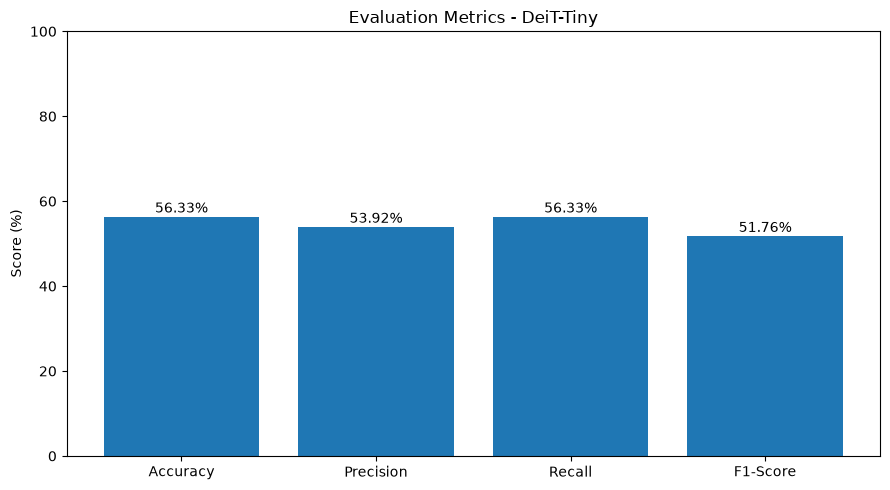

In [5]:
import matplotlib.pyplot as plt

metrics = {
    "Accuracy": accuracy * 100,
    "Precision": precision * 100,
    "Recall": recall * 100,
    "F1-Score": f1 * 100
}

plt.figure(figsize=(9, 5))

bars = plt.bar(metrics.keys(), metrics.values())

plt.title("Evaluation Metrics - DeiT-Tiny")
plt.ylabel("Score (%)")
plt.ylim(0, 100)

for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1,
        f"{bar.get_height():.2f}%",
        ha="center"
    )

plt.tight_layout()
plt.show()

In [ ]:
import pandas as pd
from sklearn.metrics import classification_report

report = classification_report(
    all_labels,
    all_predictions,
    labels=list(range(len(class_names))),
    target_names=class_names,
    output_dict=True,
    zero_division=0
)

df_report = pd.DataFrame(report).T

# Ambil hanya baris kelas, bukan accuracy atau rata-rata
df_classes = df_report.iloc[:len(class_names)].copy()

# Urutkan berdasarkan F1-score terendah
df_classes = df_classes.sort_values("f1-score")

print("10 KELAS DENGAN PERFORMA TERENDAH")
display(df_classes.head(10).round(4))

print("\n10 KELAS DENGAN PERFORMA TERTINGGI")
display(df_classes.tail(10).sort_values("f1-score", ascending=False).round(4))